# Notebook zur Faltung / CNNs

## 1d Konvolution

Wir definieren eine Reihe von Funktionen, mit denen wir gleich die Faltung eines Signals vornehmen werden.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve

x = np.linspace(-6, 6, 1000)

def peak(x):
    return 1*(np.abs(x) < 0.025)

def constant_one(x):
    return np.ones_like(x)

def constant_zero(x):
    return np.zeros_like(x)

def gaussian(x, mean=0, sigma=1):
    return np.exp(-np.power(x - mean, 2.) / (2 * np.power(sigma, 2.)))

def gaussian_narrow(x):
    return gaussian(x, sigma=0.1)

def heaviside_step(x):
    return np.heaviside(x, 0.5)

def linear(x):
    return x

def sine(x):
    return np.sin(x)

def exponential(x):
    return np.exp(x)

def square(x):
    return (np.sign(gaussian(x) - 0.5) + 1) / 2

def triangle(x):
    return np.maximum(1 - np.abs(x), 0)

# List of functions
functions = [peak, triangle, square, gaussian, gaussian_narrow,
             constant_zero, constant_one, heaviside_step,
             linear, sine, exponential]

In [2]:
import pandas as pd
df = pd.read_csv("./ASML.csv", sep=',', decimal='.', parse_dates=['Date'])
df = df.sort_values('Date')

def plot_asml(df):
    times = df['Date'].to_numpy()
    data = df['Close']
    endtime, starttime = [np.datetime_as_string(time, unit='D') for time in (times[-1], times[0])]
    description = f"ASML Holding N.V. in USD (Yahoo Finance) {starttime} -- {endtime}"
    fig, ax = plt.subplots(1,1, figsize=(9,4), dpi=600)
    ax.set_title(description)
    ax.plot(times, data, linewidth=0.5)
    indices = np.linspace(0, len(df) - 1, 9, dtype=int)
    selected_dates = df['Date'].iloc[indices]
    ax.set_xticks(selected_dates)
    ax.set_xticklabels(selected_dates.dt.strftime('%Y-%m'))
    ax.set_xlim(df['Date'].min(), df['Date'].max())
    ax.locator_params(axis='y', nbins=15)
    fig.autofmt_xdate()
    ax.set_ylabel("Close Price (USD)")
    ax.set_xlabel("Date")

Das Signal, welches wir untersuchen ist der ASML Aktienkurs in US-Dollar (closing price adjusted for splits).

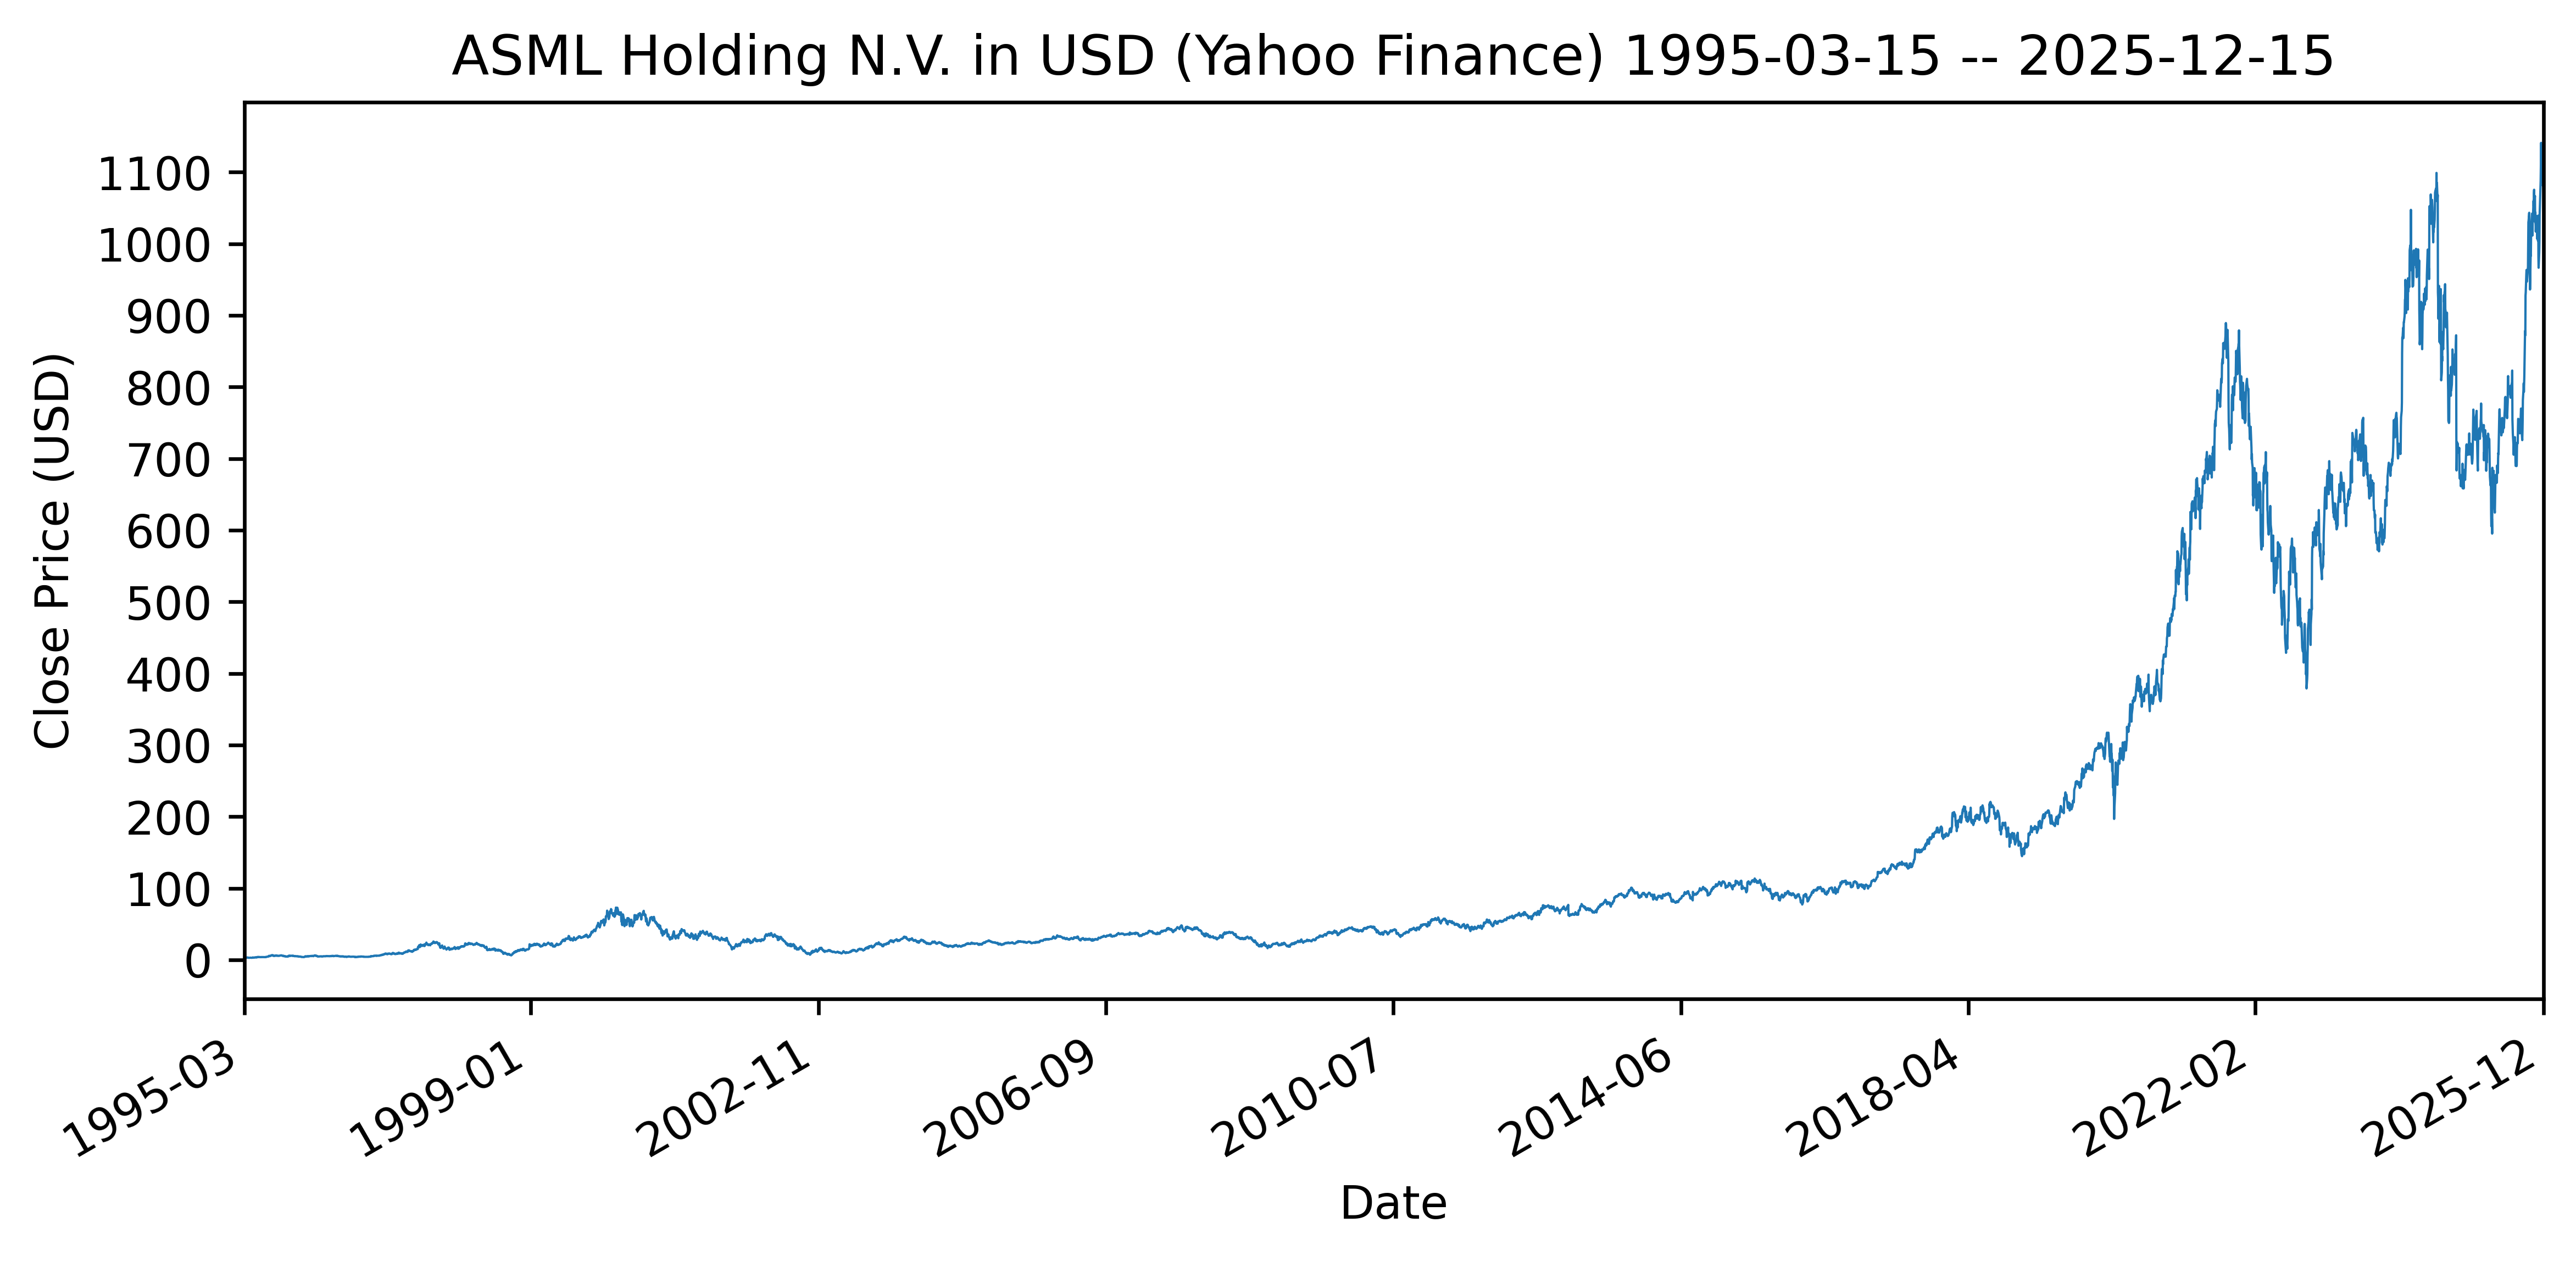

In [3]:
plot_asml(df)
plt.savefig("asml.png", transparent=True)
plt.show()

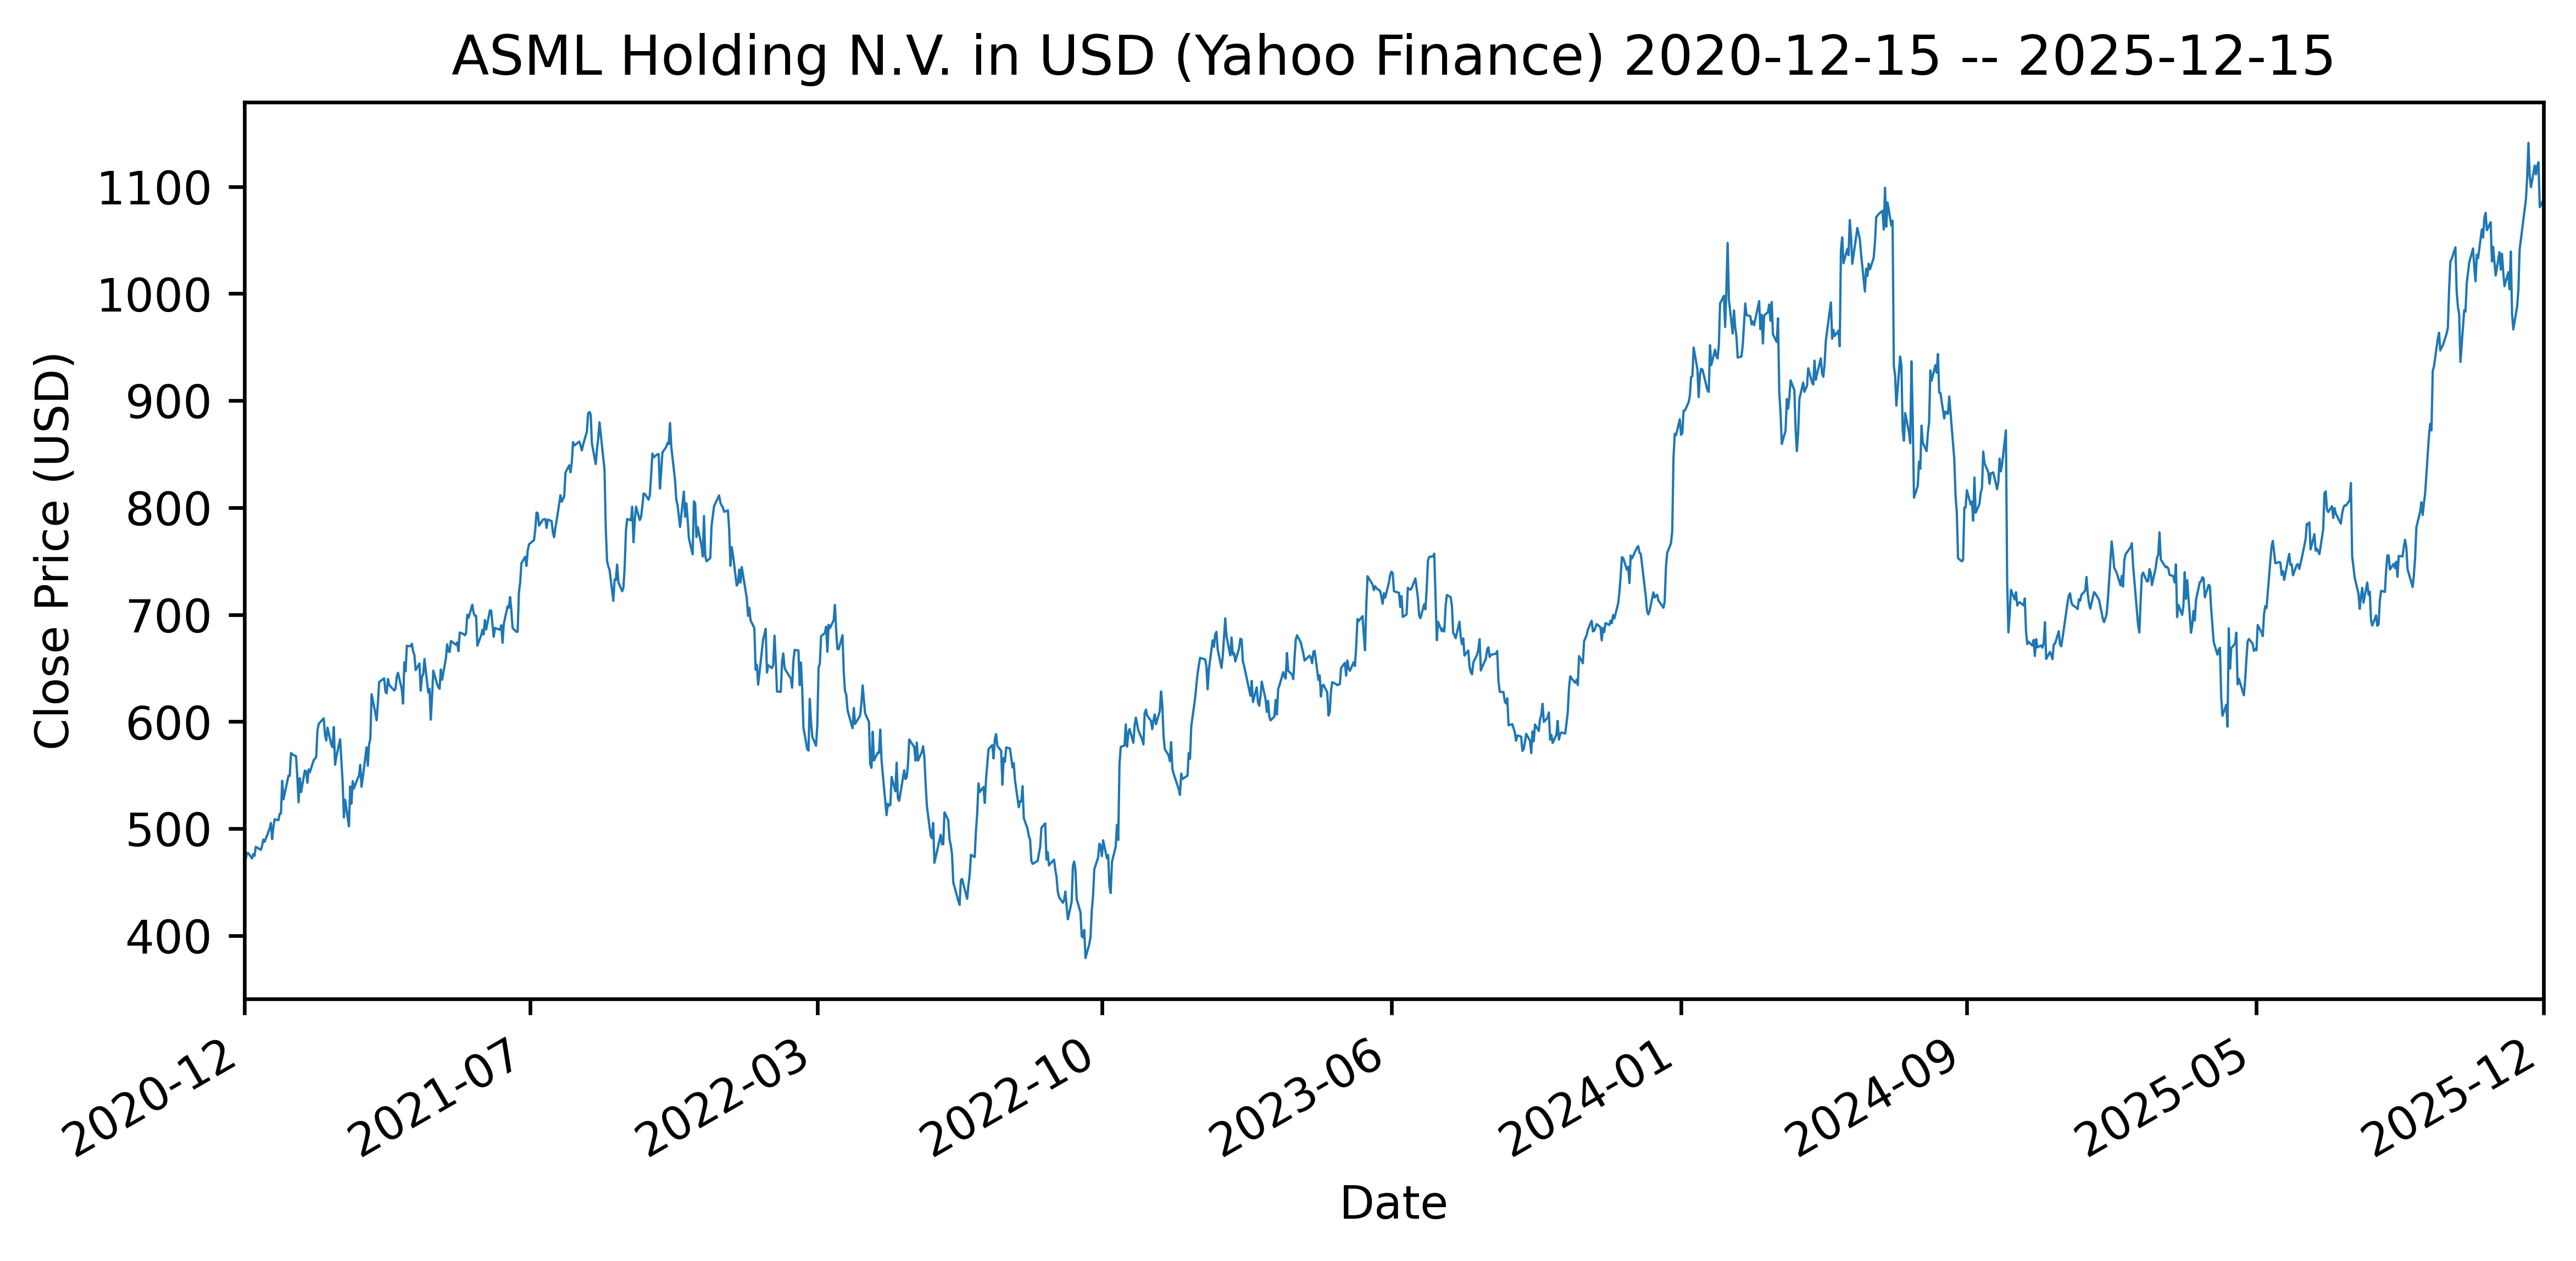

In [4]:
df_subset = df.loc[(df['Date'] >= "2020-12-15") & (df['Date'] <= "2025-12-15")]
plot_asml(df_subset)
plt.savefig("asml.png", transparent=True)
plt.show()

Um es etwas übersichtlicher zu halten, wählen wir einen Teildatensatz über 5 Jahre hinweg aus.

In [5]:
data = df_subset['Close'].to_numpy()
data_x = df_subset['Date'].to_numpy()

In [6]:
fig, axes = plt.subplots(len(functions), 2, figsize=(15, 20), dpi=600)

for i, func in enumerate(functions):
    func_values = func(x)
    
    # Original function
    axes[i, 0].plot(x, func_values)
    axes[i, 0].set_title(f"{func.__name__} Function")

    # Convolution result
    normalization = sum(func_values) or 1 # avoid divide by zero
    convolution_result = convolve(data, func_values, mode='same') / normalization
    axes[i, 1].plot(data_x, convolution_result)
    axes[i, 1].set_title(f"Convolution of data with {func.__name__}")

plt.tight_layout()
plt.savefig("convolutions.png", transparent=True)
plt.show()

Wenn $f : [-n,n] \to \mathbb{R}$ und $g : [0,N] \to \mathbb{R}$, dann ist $f \ast g : [0,N] \to \mathbb{R}$ definiert durch

$$(f \ast g)(x) = \sum_{y=-n}^n f(y) g(x-y)$$

wobei der Definitionsbereich von $g$ erweitert wird mit $0$.

*Eine* Interpretation: $g$ ist das Signal, $f$ der sogenannte Integralkern.

In Schritt $x=0$ berechnen wir $(f\ast g)(0) = \sum_{y=-n}^n f(y) g(-y) = \sum_{y=n}^{-n} f(-y) g(y)$.

Wir sehen: da wird ein Skalarprodukt berechnet! Verwirrend ist lediglich, dass die ursprüngliche Definition ein anderes Vorzeichen hatte; es ist hier aber nützlich, sich vorzustellen dass das Signal (die Daten) bleiben, wie sie sind (daher $g(y)$) und der Integralkern gespiegelt wird (daher $f(-y)$ statt $f(y)$). Rechnerisch ist es das selbe wie die Definition!

Im  Schritt $x=1$ ist es fast genau so, nur dass hier $(f\ast g)(0) = \sum_{y=-n}^n f(y) g(1-y) =  \sum_{y=n}^{-n} f(-y) g(y+1)$
das Skalarprodukt ist, wir schieben also das Fenster einen weiter.

### Was zum Teufel soll das mit der Faltung?

Das Faltungstheorem besagt für zwei Funktionen $g,h$ und die Fouriertransformation $\mathcal{F}$ und die stetige Faltung (Integral statt Summe):
$$\mathcal{F}(g \ast h) = \mathcal{F}(g) \cdot \mathcal{F}(h)$$
In Worten: Die normale Multiplikation ist die Fouriertransformation der Faltung,
oder umgekehrt: die Faltung ist die inverse Fouriertransformation der Multiplikation.

In anderen Worten: Faltung im Ortsraum ist Multiplikation im Frequenzraum.

Konkretes Beispiel: mit einer reinen Sinuswelle falten ist, wie den Koeffizienten der entsprechenden Welle in der Zerlegung des Signals in Sinuswellen herausgreifen.

Übrigens gilt auch: $(g \ast h) \ast f = g \ast (h \ast f)$.

Mit Hilfe des Faltungstheorems (und etwas mehr Mathematik) kann man auch Zeigen:
$$ \frac{d}{dx} (g \ast h) = \Big(\frac{d}{dx} g\Big) \ast h = g \ast \Big(\frac{d}{dx} h\Big)$$

## 1d Pooling

1d Average Pooling ist im Grunde eine Variante von Binning:

Beim Binning zerlegt man einen Array in feste Blöcke ohne Überlapp und nimmt den Mittelwert (typischerweise).
Das ist wie eine Faltung mit einer Kastenfunktion, bei der man nun aber nur ein paar Werte verwendet, sodass man die Kästen ohne Überlapp betrachtet.
Der Parameter, wie viel Überlapp, heißt auch *stride* (Schritt / langer Schritt).

Es gibt nicht nur Average Pooling sondern auch Max Pooling, wo man nicht mit einer Kastenfunktion faltet sondern pro Pool (das gleiche wie ein Bin, nur eben dass Überlapp erlaubt ist) das jeweilige Maximum auswählt.

Pooling dient dazu, die Datenmenge zu reduzieren indem pro Pool eine summative Statistik (Average, Max, etc.) berechnet wird. Die genaue Position des Werts tritt etwas in den Hintergrund durch das Pooling.

## 1d CNNs

Wir verwenden die PyTorch Funktion `conv1d` um eine eindimensionale Faltung auszurechnen:

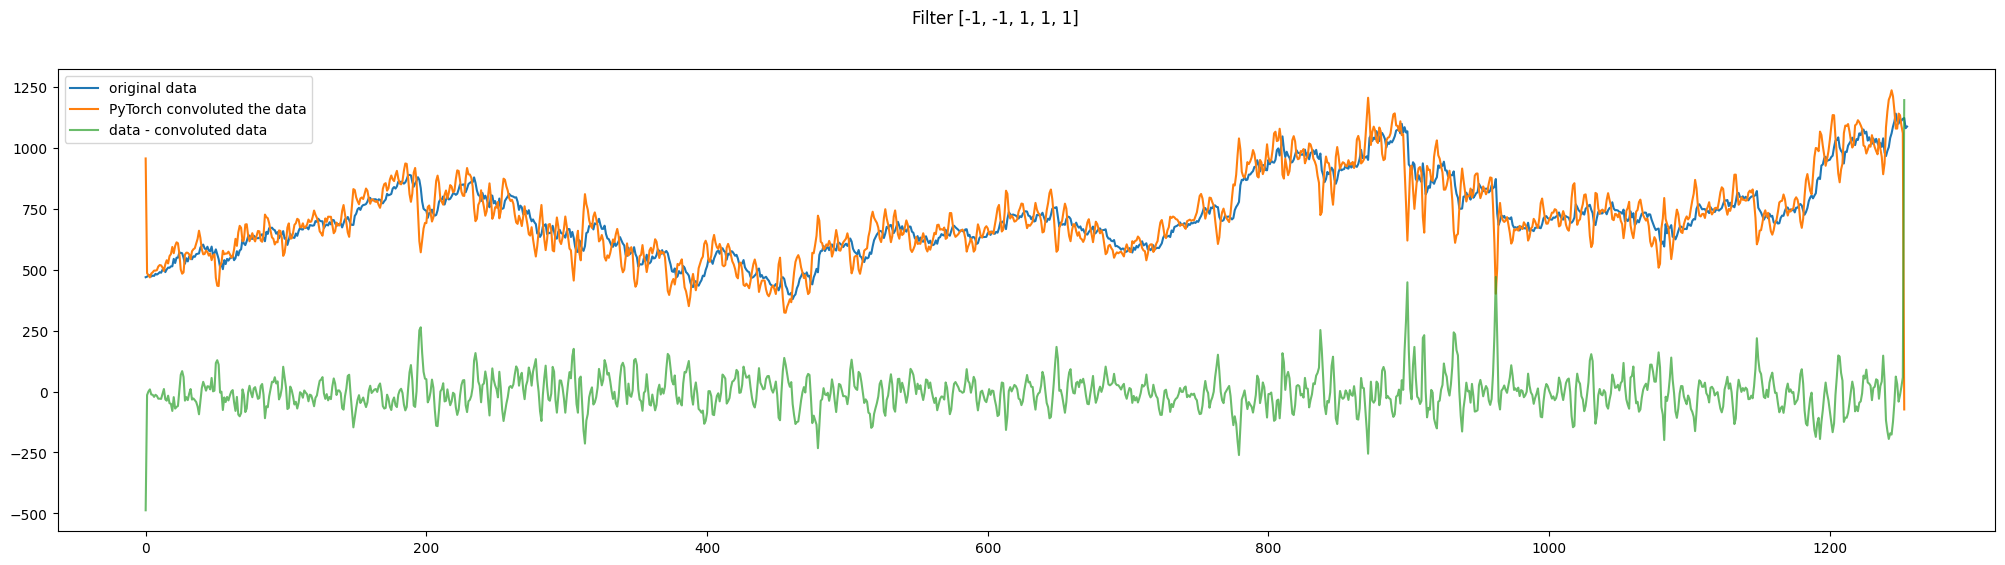

In [7]:
import torch
import torch.nn.functional as F

def show_filter_results(filter_weights, weight_format_pattern=".2f"):
    # Convert the data to a PyTorch tensor and add required dimensions for batch and in_channels
    # Shape of input data should be (batch_size, in_channels, sequence_length)
    data_tensor = torch.FloatTensor(data).unsqueeze(0).unsqueeze(0)

    # padding = kernel_size // 2 keeps the output length equal to the input length
    output = F.conv1d(data_tensor, filter_weights, padding=filter_weights.shape[-1] // 2)
    output_array = output.squeeze(0).squeeze(0).numpy()

    fig, ax = plt.subplots(1, 1, figsize=(25, 6))
    pretty_filter_values = [format(fw, weight_format_pattern) for fw in (filter_weights.reshape(-1).tolist())]
    fig.suptitle(f"Filter [{', '.join(pretty_filter_values)}]")
    ax.plot(data, label="original data")
    ax.plot(output_array, label="PyTorch convoluted the data")
    ax.plot(data[0:len(output_array)] - output_array, label="data - convoluted data", alpha=0.7)
    ax.legend()
    plt.show()

show_filter_results(filter_weights = torch.tensor([-1.0, -1, 1, 1, 1]).view(1, 1, 5), weight_format_pattern=".0f")

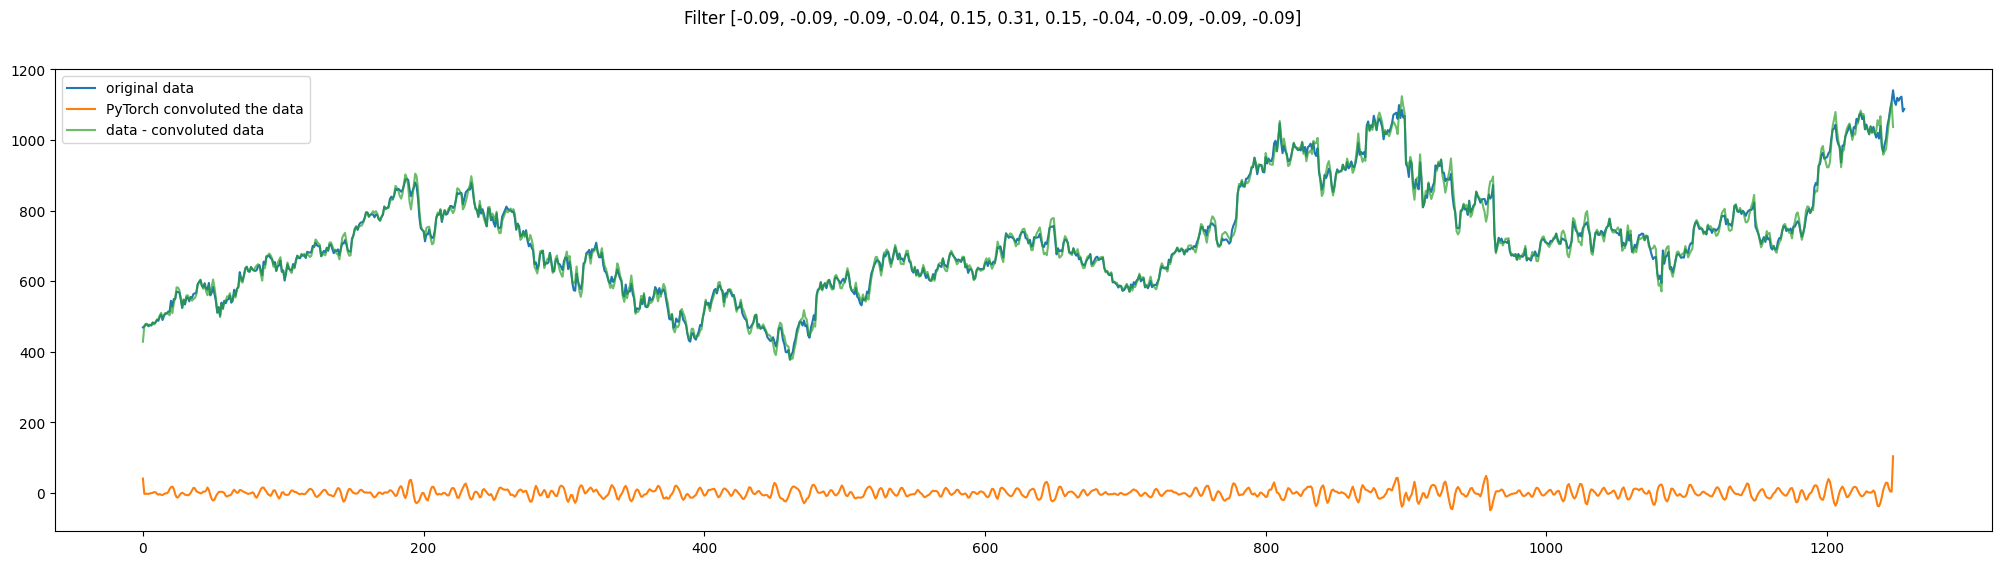

In [8]:
def gaussian_1d(kernel_size, sigma):
    """Returns a 1D Gaussian kernel."""
    x = torch.arange(kernel_size).float() - kernel_size // 2
    gauss_kernel = torch.exp(-x.pow(2) / (2 * sigma ** 2))
    return gauss_kernel / gauss_kernel.sum()

# Define kernel size and standard deviations for the two Gaussians
kernel_size = 11  # A larger kernel_size would capture more context
sigma1 = 1
sigma2 = 20

# Create two Gaussian filters
gaussian1 = gaussian_1d(kernel_size, sigma1)
gaussian2 = gaussian_1d(kernel_size, sigma2)

# Subtract the second Gaussian from the first to create the DoG filter
dog_filter = gaussian1 - gaussian2
# Reshape dog_filter to have dimensions [out_channels, in_channels, kernel_size]
show_filter_results(filter_weights = dog_filter.view(1, 1, -1))

## 2d CNNs

Wir benutzen PyTorch's `Conv2d` um eine zweidimensionale Faltung auszurechnen.

tensor([[-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.],
        [-1.,  7.,  7.,  7., -1.],
        [-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.]])


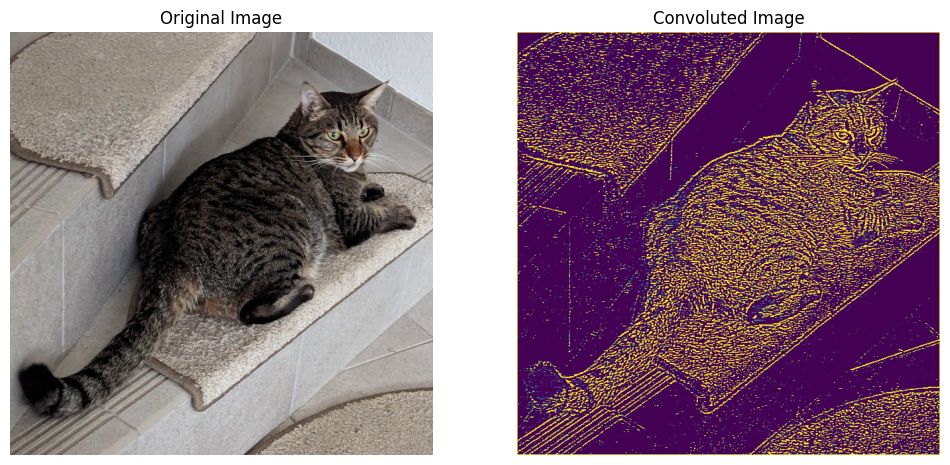

In [9]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt

# Step 1: Load the image
image_path = 'pallino.jpg'
image = Image.open(image_path)

# Step 2: Convert the image to a PyTorch tensor
transform = transforms.Compose([
    transforms.ToTensor(),
])
image_tensor = transform(image)

# Add a batch dimension since PyTorch convolution expects a batch in the input
image_tensor = image_tensor.unsqueeze(0)

# Step 3: Define a convolution layer with the specified weights
conv_layer = nn.Conv2d(in_channels=3, out_channels=3, kernel_size=5, padding=1, bias=False)

# Set the weights: 5x5 matrix with -1 everywhere except in the center etc.
weights = torch.full((5, 5), -1.0)
#weights[1, 2] = 0
#weights[3, 2] = 0
weights[2, 1] = 7
weights[2, 3] = 7
weights[2, 2] = 7.0
print(weights)
weights = weights.unsqueeze(0).unsqueeze(0) # Add channel and batch dimensions
weights = weights.repeat(1, 3, 1, 1) # Repeat weights for each input channel

# Assign the weights to the convolution layer
conv_layer.weight.data = weights

# Step 4: Apply the convolution layer to the image
convoluted_image = conv_layer(image_tensor)

# Remove batch dimension and convert back to PIL image for display
convoluted_image = torch.clamp(convoluted_image, 0.0, 1.0)
convoluted_image = convoluted_image.squeeze(0)
convoluted_image_pil = transforms.ToPILImage()(convoluted_image)

# Step 5: Display the original and convoluted images
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(convoluted_image_pil)
plt.title("Convoluted Image")
plt.axis('off')

plt.show()

--> [Animationen](https://github.com/vdumoulin/conv_arithmetic/blob/master/README.md)

--> [Interaktives MNIST CNN von Adam Harley](https://adamharley.com/nn_vis/cnn/2d.html)

--> [Universal Fourier Features Emerge](https://arxiv.org/pdf/2312.08550.pdf)